# DLENT-RT — model check (week 33)

This notebook checks the final model decisions D1–D6 on `configs/default.yaml`, the one configuration. It
replaces the old notebooks 01 (Phase 0 diagnostics) and 05 (theoretical models).

Each section has a short introduction, then a PASS / FAIL table, then the results. The logic is in
`dlent_rt/diagnostics.py`. Three long computations are cached by `scripts/model_check_cache.py` in
`reports/week33/cache/`: the f scan, the one-week bucketed MILP (3,600 s, its own process) and the one
theoretical DLENT-RT run. Without the cache, this notebook computes them itself (about 1.5 hours).

Build: `dlent_venv/bin/python notebooks/src/build.py 01_model_check --execute`.

In [1]:
import pickle, subprocess, sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dlent_rt").is_dir())
sys.path.insert(0, str(ROOT))
warnings.simplefilter("ignore")
pd.set_option("display.width", 200, "display.max_columns", 30, "display.float_format", lambda x: f"{x:,.6g}")

from dlent_rt import diagnostics as dg
from dlent_rt import theory_eval as te
from dlent_rt.benchmarks import Benchmarks, enlarge_for_job_models
from dlent_rt.config import default_config
from dlent_rt.data import load_dataset
from dlent_rt.models.core.stream import build_stream
from dlent_rt.phase0 import run_phase0

CACHE = ROOT / "reports" / "week33" / "cache"
BLUE, ORANGE, INK, INK2, GRID = te.BLUE, te.ORANGE, te.INK, te.INK2, te.GRID
RESULTS = {}                      # (decision, item) -> PASS / FAIL, for the checklist of section 11


def show(tab, keys=None):
    """Display a PASS / FAIL table and record its results for the checklist."""
    display(tab)
    for (d, w), rows in (keys or {}).items():
        RESULTS[(d, w)] = "PASS" if all(tab.loc[tab.check.isin(rows), "result"] == "PASS") else "FAIL"


def style(ax, xlabel, ylabel=None, log=False):
    if log:
        ax.set_xscale("log")
    ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    ax.grid(axis="y", color=GRID, lw=0.6)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)


def cached(name, compute):
    path = CACHE / name
    if path.is_file():
        with open(path, "rb") as fh:
            return pickle.load(fh)
    print(f"{name}: no cache, computing it now")
    subprocess.run([sys.executable, str(ROOT / "scripts" / "model_check_cache.py"), compute], check=True, cwd=ROOT)
    with open(path, "rb") as fh:
        return pickle.load(fh)


CFG = default_config()
COMMIT = subprocess.check_output(["git", "-C", str(ROOT), "rev-parse", "--short", "HEAD"], text=True).strip()
DS = load_dataset(CFG)
ST = run_phase0(DS, CFG)
B = Benchmarks(DS, ST, CFG)
S = B.S
print(f"commit {COMMIT}; config configs/default.yaml; f = {CFG.capacity.f}; |H| = {DS.H.n:,}; |stream| = {S.n:,}")

commit 53c19cf; config configs/default.yaml; f = 0.5; |H| = 44,719; |stream| = 241,475


## 1. Data and limits

The jobs come from `data/batch_v2_300k.csv` (a uniform 300k sample of May 2019). Each job has one duration: the
effective duration (CPU-hours / CPU request), floored at 1 minute and cut at 24 h. Jobs are cut, not removed.
The only rule that removes jobs is the job quota: a job asks for more than Q = 0.2 C on some resource. There
are no outlier filters. H is the first 7 days; the stream is the rest.

In [2]:
RAW = dg.raw_jobs(CFG)
tab, summ = dg.checks_data(DS, CFG, RAW)
show(tab, {("D3", "24 h cap and 1-minute floor"): ["durations inside [1 minute, 24 h]",
                                                    "duration = effective duration (CPU-hours / CPU), floored and capped"],
           ("D3", "H = first 7 days"): ["H = the jobs of the first 7 days"]})
display(pd.Series(summ, name="value").to_frame())
display(dg.stats_table({"CPU request (machines)": DS.H.A[:, 0], "RAM request (machines)": DS.H.A[:, 1],
                        "duration (h)": DS.H.duration_hours, "work r x d (CPU machine-h)": DS.H.A[:, 0] * DS.H.duration_hours}))

,check,result,detail
0,only the quota removes jobs (no outlier filter),PASS,"300,000 = 286,194 kept + 13,806 over the quota"
1,every kept request <= Q,PASS,"max CPU 0.1252 <= 0.1252, max RAM 0.0850 <= 0...."
2,"durations inside [1 minute, 24 h]",PASS,"min 1.000 min, max 24.000 h"
3,duration = effective duration (CPU-hours / CPU...,PASS,same multiset of durations
4,H = the jobs of the first 7 days,PASS,"H ends 2019-05-08 06:59:32, stream starts 2019..."
5,d_max = 24 h and d_max / T <= 0.10,PASS,d_max / T = 0.0417


,value
jobs in the file,300000
rejected by the quota,13806
jobs kept,286194
H (first 7 days),44719
stream,241475
stream horizon T (h),575.899
kept jobs cut by the 24 h cap,755
kept jobs raised to 1 minute,113681
"quota Q (machines), CPU / RAM","[0.12518724735715756, 0.08502414439576123]"
d_max (h),24


,quantity,count,mean,p10,p50,p90,p99,max
0,CPU request (machines),44719,0.0128096,0.00228882,0.00695801,0.0333471,0.08255,0.12488
1,RAM request (machines),44719,0.00780226,0.00143814,0.00562286,0.018219,0.0543213,0.0850048
2,duration (h),44719,0.352884,0.016667,0.016667,0.484722,5.03194,24
3,work r x d (CPU machine-h),44719,0.00470236,4.991e-05,0.000171835,0.00415218,0.0825186,2.76123


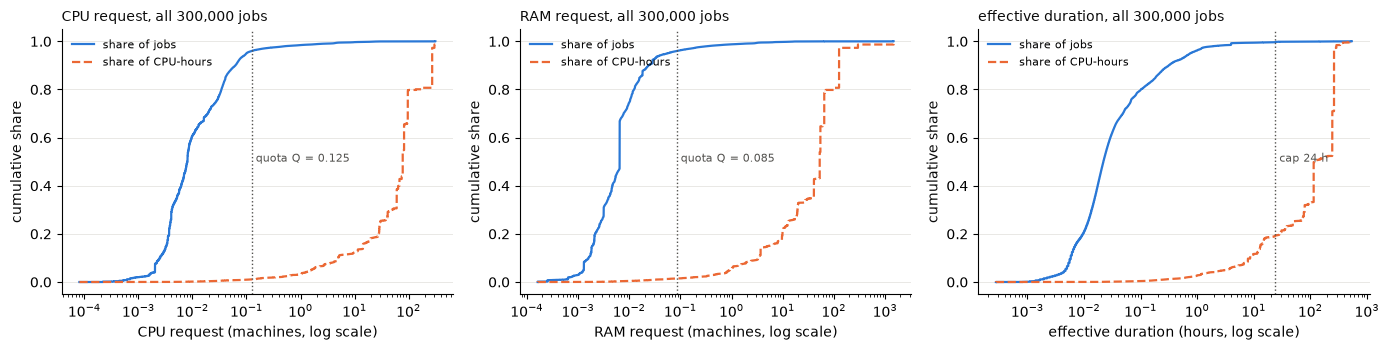

In [3]:
J = te.job_distributions(CFG)
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, which in zip(axs, ("cpu", "ram", "duration")):
    te.fig_cdf_jobs_work(J, which, ax)
plt.tight_layout(); plt.show()

**Reading.** The cap and the quota change little of the work. The table below gives the shares of jobs and of
CPU-hours they remove or cut.

In [4]:
display(J["impact"])

,set,jobs,CPU-hours (effective),jobs cut by the 24 h cap,share of jobs cut,CPU-hours cut by the cap,jobs removed by the quota,share of jobs removed,CPU-hours removed by the quota,CPU-hours left after both
0,all 300k,300000,"187,573",901,0.00300333,0.659093,13806,0.04602,0.989807,0.00551008
1,H (first 7 days),47909,"16,185.9",247,0.00515561,0.460975,3190,0.0665846,0.971572,0.0129919


## 2. Bid and U0 calibration

D2: cost_base_j = (U0 (1 + ln q_j) + γ1 cores_j + γ2 GB_j) d_j, and the bid v_j is lognormal with mean
cost_base_j and σ = 0.3. U0 is in $ per hour per job. It is the cost rate γ1 cores + γ2 GB of the median job
of H, ranked by that rate. It is computed once in Phase 0 and then fixed for the stream. γ1 = 0.0332 $/vCPU-h,
γ2 = 0.00445 $/GiB-h, cores = CPU × 64, GB = RAM × 256.

In [5]:
tab, summ = dg.checks_bid(DS, ST, CFG, S)
show(tab, {("D2", "cost_base = (U0 (1 + ln q) + g1 cores + g2 GB) d"): ["cost_base = (U0 (1 + ln q) + gamma1 cores + gamma2 GB) d, H",
                                                                        "cost_base formula, stream"],
           ("D2", "U0 = rate of the median H job"): ["U0 = gamma1 cores + gamma2 GB of the median H job",
                                                     "U0 is the same for H and the stream (fixed after Phase 0)"]})
display(pd.Series(summ, name="value").to_frame())
BF = dg.bid_frame(DS, ST, CFG)
display(dg.bid_tier_table(BF))

,check,result,detail
0,U0 = gamma1 cores + gamma2 GB of the median H job,PASS,U0 = 0.02138 $/h; the job at the middle positi...
1,U0 is the same for H and the stream (fixed aft...,PASS,Phase 0 state U0 = 0.02138
2,cost_base = (U0 (1 + ln q) + gamma1 cores + ga...,PASS,recomputed by hand
3,"cost_base formula, stream",PASS,recomputed by hand
4,"mean bid = cost_base (mean markup 1, within 1%)",PASS,mean markup 1.0012


,value
U0 ($ per hour per job),0.021382
median H job: cores / GB,"[0.4340820312499968, 1.56640625]"
median H job: gamma1 cores + gamma2 GB,0.021382
mean markup v / cost_base (H),1.00116
std of ln markup (H),0.300994


,priority,jobs,1 + ln q,mean bid $,mean cost base $,mean bid per hour $,phi < 0 %
0,1,981,1,0.0203155,0.0190024,0.0582201,16.106
1,2,3430,1.69315,0.0483216,0.0483795,0.0798225,16.7347
2,3,2001,2.09861,0.0698834,0.0650104,0.0920679,16.3918
3,4,38179,2.38629,0.0267147,0.0268717,0.08593,16.7474
4,5,128,2.60944,0.155106,0.165065,0.0873283,14.8438


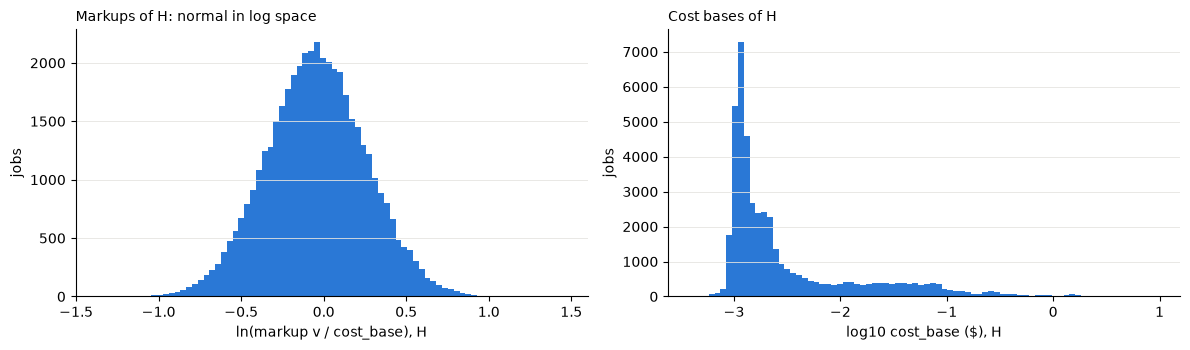

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
axs[0].hist(np.log(BF.markup), bins=80, color=BLUE)
style(axs[0], "ln(markup v / cost_base), H", "jobs")
axs[0].set_title("Markups of H: normal in log space", loc="left", fontsize=10)
axs[1].hist(np.log10(BF.cost_base), bins=80, color=BLUE)
style(axs[1], "log10 cost_base ($), H", "jobs")
axs[1].set_title("Cost bases of H", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

**Reading.** U0 is small because the median job is small: most jobs ask for a few hundredths of a machine. The
bid grows with priority through (1 + ln q) only.

## 3. Virtual value

φ_j = cost_base_j · φ_m(v_j / cost_base_j), with φ_m(m) = m − (1 − F(m)) / f(m) for the lognormal markup
(μ = −σ²/2). Two facts must hold: E[φ_m] = 0 (exactly, by integration by parts) and φ_m increasing (a regular
distribution). The theoretical model refits σ on the markups: on H in Phase 0, and on the previous phase's
arrivals at every ReInit. The no-learning model keeps σ = 0.3.

In [7]:
RUN = cached("theory_run.pkl", "theory")
tab, summ = dg.checks_phi(ST, CFG, phase_sigmas=RUN["phases"].sigma.to_numpy())
show(tab, {("D2", "sigma refit in Phase 0"): ["sigma refit on H within 0.01 of 0.3"],
           ("D2", "sigma refit at ReInit"): ["sigma refit at every ReInit within 0.01 of 0.3"],
           ("D2", "phi = cost_base phi_m(v / cost_base)"): ["E[phi_m] = 0 by quadrature (sigma = 0.1, 0.3, refit, 0.5)",
                                                           "phi_m increasing (z in [-6, 6])"]})
display(pd.Series(summ, name="value").to_frame())
print(f"sample mean of phi / cost_base over H: {(BF.phi / BF.cost_base).mean():.3f} (positive: the negative mass that "
      f"balances E[phi_m] = 0 sits in markups below 1 in a million draws)")

,check,result,detail
0,"E[phi_m] = 0 by quadrature (sigma = 0.1, 0.3, ...",PASS,"0.1000: 2.5e-03, 0.3000: 1.5e-08, 0.3010: 1.4e..."
1,"phi_m increasing (z in [-6, 6])",PASS,min step 1.30e-03
2,sigma refit on H within 0.01 of 0.3,PASS,refit sigma = 0.3010
3,sigma refit at every ReInit within 0.01 of 0.3,PASS,"16 phases, sigma in [0.2961, 0.3032]"


,value
E_phi,"{0.1: 0.0024663893486089883, 0.3: 1.4559822236..."
sigma_refit,0.300994
reserve_markup,0.714939


sample mean of phi / cost_base over H: 0.196 (positive: the negative mass that balances E[phi_m] = 0 sits in markups below 1 in a million draws)


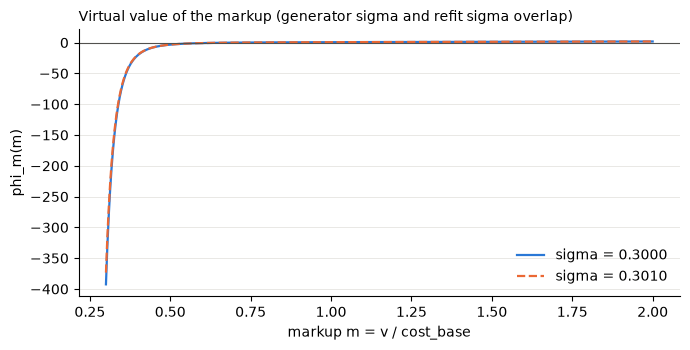

In [8]:
m = np.linspace(0.3, 2.0, 400)
fig, ax = plt.subplots(figsize=(7, 3.6))
from dlent_rt.bid import MyersonModel
for s, col, ls in ((CFG.bid.sigma, BLUE, "-"), (ST.myerson.sigma, ORANGE, "--")):
    ax.plot(m, MyersonModel.known_markup(s).phi_markup(m), color=col, ls=ls, lw=1.6, label=f"sigma = {s:.4f}")
ax.axhline(0, color=INK2, lw=0.8)
style(ax, "markup m = v / cost_base", "phi_m(m)")
ax.set_title("Virtual value of the markup (generator sigma and refit sigma overlap)", loc="left", fontsize=10)
ax.legend(frameon=False); plt.tight_layout(); plt.show()

## 4. Objectives

D1: customer value V = v (no priority factor), profit Π = φ − C_elec, carbon = s_C · K, and the reward
R = λ1 V + λ2 Π − λ3 s_C K with all λ = 1 (linear). s_C = D_q / K_q, D_q = (Q_0.9(V) + Q_0.9(|Π|)) / 2,
K_q = Q_0.9(K), p-weighted over H's types, computed once in Phase 0. Social welfare is a metric only:
SW = Σ_admitted (v − C_elec − s_C K). Priority enters only the bid.

In [9]:
tab, summ, TERMS = dg.checks_objectives(DS, ST, CFG, S)
show(tab, {("D1", "V = v (no q factor); Pi = phi - C_elec; carbon = s_C K"): ["customer value V = v (no priority factor), stream"],
           ("D1", "R = l1 V + l2 Pi - l3 s_C K, linear, all lambda = 1"): ["all lambda = 1", "r~ = V + Pi - s_C K (linear, per type)"],
           ("D1", "s_C = D_q / K_q over H's types, once in Phase 0"): ["s_C = D_q / K_q, D_q = (Q_0.9(V) + Q_0.9(|Pi|)) / 2, recomputed"],
           ("D1", "SW metric only"): ["SW = v - C_elec - s_C K per job (metric only)"]})
display(pd.Series(summ, name="value").to_frame())

,check,result,detail
0,all lambda = 1,PASS,"(1.0, 1.0, 1.0)"
1,"r~ = V + Pi - s_C K (linear, per type)",PASS,max abs diff 0.0e+00
2,"s_C = D_q / K_q, D_q = (Q_0.9(V) + Q_0.9(|Pi|)...",PASS,s_C = 11.8917 $/kg
3,"customer value V = v (no priority factor), stream",PASS,job_terms(...).cv is the bid
4,SW = v - C_elec - s_C K per job (metric only),PASS,reward.job_terms(...).sw; no decision reads it
5,priority enters only the bid: cost_base / rate...,PASS,"hand-made jobs, q = 1..5"


,value
"term shares (sum |term|, p-weighted)","{'customer value': 0.35161670464935946, 'profi..."
sum p V / sum p |Pi| over H's types,1.23102
Q_0.9(V) $,0.0376407
Q_0.9(|Pi|) $,0.0184295
D_q $,0.0280351
K_q kg,0.00235754
s_C $/kg,11.8917
lambda,"(1.0, 1.0, 1.0)"


**Reading.** The shares say how much of Σ|term| each term carries over H's types. The ratio ΣpV / Σp|Π| says how
the customer value compares with the profit. s_C is in $ per kg CO2 and follows the dollar level of the bids.

## 5. Grid

D4: a geometric grid on bids, L_k = v_min ρ^k, ρ = (v_max / v_min)^(1/128), with v_min / v_max the smallest /
largest bid. There is no fixed floor (only a guard against bids ≤ 0). The theoretical model rebuilds the grid at
every ReInit; the no-learning model keeps Phase 0's grid. Rounding a bid down to its bin edge loses at most
1 − 1/ρ of it.

In [10]:
tab, summ = dg.checks_grid(ST, CFG)
show(tab, {("D4", "geometric grid between the smallest and largest bid, no floor"): list(tab.check)})
display(pd.Series(summ, name="value").to_frame())

,check,result,detail
0,"bins cover every bid: bin 1 = [0, L_1), bin K*...",PASS,"a bid of 0, one below v_min and one above v_max"
1,"v_min = smallest bid, v_max = largest bid (no ...",PASS,"v_min = 2.308e-04, v_max = 1.168e+01"
2,edges geometric: L_k = v_min rho^k,PASS,rho = 1.08831
3,K* = 128 bins,PASS,128
4,every bid has a bin,PASS,124 of 128 bins used


,value
v_min $,0.000230827
v_max $,11.6831
rho,1.08831
K*,128
bins used by H,124
worst-case loss 1 - 1/rho,0.0811431


## 6. Cluster and quota

D3: D̄_i = Σ_H r_ij d_j / |H|, C_i = f · D̄_i, and Q_i = 0.2 · C_i of the cluster actually used (a fixed point:
Q sets which jobs are kept, the kept jobs set D̄). f follows a rule with two conditions, in priority order, over
f ∈ {0.3, 0.35, 0.4, 0.45, 0.5}:

* (a) REQUIRED: τ > 0 (CPU or RAM) in both the Phase 0 LP and fluid OPT;
* (b) among the f that pass (a): the static Phase 0 policy's "% of the time ≥ 95% full" closest to the 20–30% band.

The rule was made explicit after the preview of this notebook (week 33): the first version ranked by (b) only,
over a scan up to f = 0.6, and picked f = 0.6, where τ = 0.

In [11]:
SCAN = cached("f_scan.pkl", "scan")
R0 = next(r for r in SCAN["results"] if r["f"] == CFG.capacity.f)
tab, ITERS = dg.checks_cluster(DS, ST, CFG, SCAN, R0["fluid"]["tau"])
show(tab, {("D3", "C = f D_bar on H"): ["C = f x D_bar (H only)"],
           ("D3", "Q = 0.2 C fixed point at the actual f"): ["Q = 0.2 C at the fixed point (within 2%)",
                                                             "fixed point stopped with a move < 1%"]})
display(dg.scan_table(SCAN))
display(Markdown(f"**Fixed point at f = {CFG.capacity.f}** (Q in machines):"))
display(ITERS)

,check,result,detail
0,C = f x D_bar (H only),PASS,"f = 0.5, D_bar = [1.2518, 0.8501]"
1,Q = 0.2 C at the fixed point (within 2%),PASS,"Q / C = [0.2, 0.2]"
2,fixed point stopped with a move < 1%,PASS,"12 steps, last move [0.0005, 0.0007]"
3,"f = the rule's pick: (a) tau > 0 in both LPs, ...",PASS,"rule picks 0.5, config f = 0.5; 44.6% of the t..."
4,tau > 0 in the Phase 0 LP (some resource),PASS,"tau = [0.0, 0.000735]"
5,tau > 0 in fluid OPT (some resource),PASS,"tau = [0.0, 0.000773]"


,f,(a) tau > 0 in Phase 0 LP and fluid OPT,(b) distance to the 20-30% band (points),C CPU,C RAM,Q CPU,Q RAM,H jobs,stream jobs,% time >= 95% full,mean occupancy / C (CPU),rejected for space %,"tau Phase 0 (CPU, RAM)","tau fluid OPT (CPU, RAM)",static reward $,fluid OPT $,picked
0,0.3,True,20.3487,0.293561,0.20037,0.0587131,0.0400743,43056,222236,50.3487,89.1649,14.9953,"[0.00019, 0.00189]","[0.00023, 0.00182]","1,162.28","2,105.11",False
1,0.35,True,19.5669,0.363261,0.25051,0.0726959,0.0501271,43675,230126,49.5669,87.9137,15.5697,"[0.0, 0.00167]","[0.0, 0.00148]",928.913,"2,167.76",False
2,0.4,True,17.9368,0.433934,0.296462,0.0867931,0.0592974,44133,234987,47.9368,87.7776,15.2898,"[0.0, 0.00116]","[0.0, 0.00124]","1,371.03","2,494",False
3,0.45,True,17.2586,0.522944,0.359058,0.104866,0.0719707,44496,239724,47.2586,86.8121,15.482,"[0.0, 0.00086]","[0.0, 0.00097]","1,457.92","2,609.48",False
4,0.5,True,14.5631,0.625886,0.425034,0.125187,0.0850241,44719,241475,44.5631,86.6274,13.5451,"[0.0, 0.00073]","[0.0, 0.00077]","1,316.92","2,843.68",True


**Fixed point at f = 0.5** (Q in machines):

,step,Q CPU,Q RAM,jobs kept,H jobs,C CPU,C RAM,move CPU %,move RAM %
0,0,4.13703,2.83841,297445,47380,5.59974,3.70369,72.9287,73.9031
1,1,1.11995,0.740738,295348,46756,1.83844,1.23693,67.1691,66.6028
2,2,0.367689,0.247386,292448,45953,1.12379,0.733676,38.8726,40.6857
3,3,0.224759,0.146735,289944,45387,0.955965,0.614085,14.934,16.3003
4,4,0.191193,0.122817,289047,45201,0.862023,0.539441,9.827,12.1554
5,5,0.172405,0.107888,288286,45078,0.784162,0.499674,9.03234,7.37176
6,6,0.156832,0.0999349,287730,44966,0.742578,0.477914,5.30291,4.35502
7,7,0.148516,0.0955827,287394,44889,0.664852,0.451031,10.4671,5.62491
8,8,0.13297,0.0902063,286791,44808,0.647281,0.443538,2.64286,1.66132
9,9,0.129456,0.0887077,286562,44774,0.628565,0.433689,2.89139,2.22062


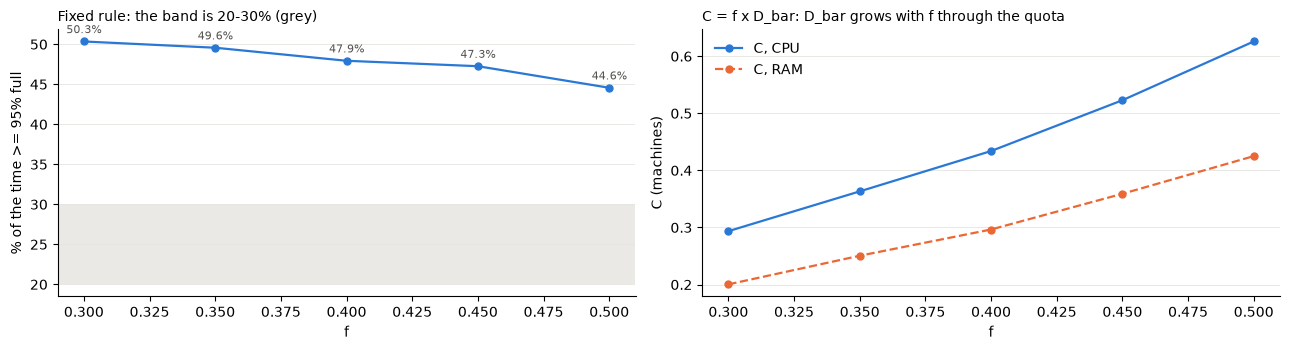

In [12]:
SC = dg.scan_table(SCAN)
fig, axs = plt.subplots(1, 2, figsize=(13, 3.6))
axs[0].axhspan(20, 30, color=GRID, alpha=0.8, lw=0)
axs[0].plot(SC.f, SC["% time >= 95% full"], color=BLUE, marker="o", ms=5, lw=1.6)
for f, y in zip(SC.f, SC["% time >= 95% full"]):
    axs[0].annotate(f"{y:.1f}%", (f, y), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=8, color=INK2)
style(axs[0], "f", "% of the time >= 95% full")
axs[0].set_title("Fixed rule: the band is 20-30% (grey)", loc="left", fontsize=10)
axs[1].plot(SC.f, SC["C CPU"], color=BLUE, marker="o", ms=5, lw=1.6, label="C, CPU")
axs[1].plot(SC.f, SC["C RAM"], color=ORANGE, marker="o", ms=5, lw=1.6, ls="--", label="C, RAM")
style(axs[1], "f", "C (machines)")
axs[1].set_title("C = f x D_bar: D_bar grows with f through the quota", loc="left", fontsize=10)
axs[1].legend(frameon=False)
plt.tight_layout(); plt.show()

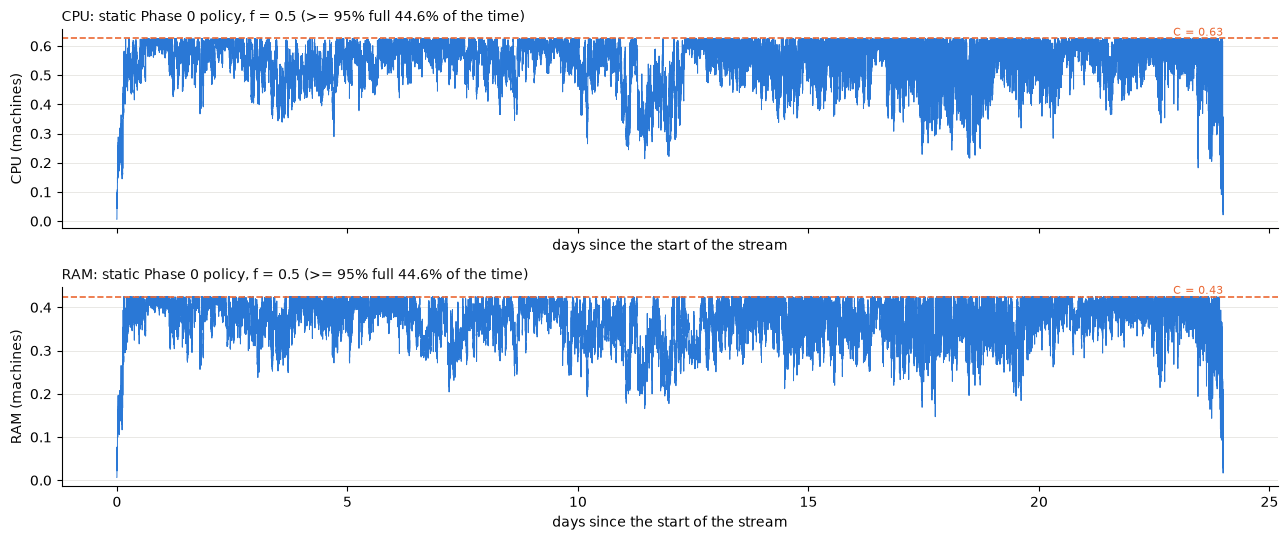

In [13]:
fig, axs = plt.subplots(2, 1, figsize=(13, 5.5), sharex=True)
te.fig_occupancy(R0, axs, CFG.time.tick_seconds)
plt.tight_layout(); plt.show()

**Job-level enlargement (D3, off by default).** The check runs Greedy-Pos (admit every job with R > 0 that fits)
only as a capacity probe. It reports the share of the positive-reward jobs it rejects for lack of space. The
option would enlarge C only if that share were above 50%.

In [14]:
ENL = RUN["job_level_check"]
chk = ENL["checks"][0]
tab = dg.check_table([("job-level enlargement off by default", not CFG.capacity.job_level_enlarge, ""),
                      ("check computed: positive-reward jobs rejected for space <= 50%", not chk["exceeds"],
                       f"{chk['n_rejected_space']:,} of {chk['n_positive']:,} = {100 * chk['share_rejected_space']:.1f}%")])
show(tab, {("D3", "job-level enlargement option and check"): ["job-level enlargement off by default"]})

,check,result,detail
0,job-level enlargement off by default,PASS,
1,check computed: positive-reward jobs rejected ...,PASS,"35,441 of 182,270 = 19.4%"


## 7. ξ and γ

The DLENT guarantee (Theorem 1) is (1 − ε_D − ξ) · OPT minus error terms, with ε_D = 2√(ξL) + 2ξL,
L = ln(|I|/δ), δ = 1/T³. It is not empty only if 1 − ε_D − ξ > 0, i.e. ξ ≤ ξ_max. The data ξ = max_i a_max,i / C_i
is far above ξ_max, so ξ = 0.001 and γ = 1 are forced (D5). Test 1 then uses the threshold (1 − ξ) c.

In [15]:
tab, summ = dg.checks_constants(DS, ST, CFG)
show(tab, {("D5", "xi = 0.001, gamma = 1 forced; Test 1 = (1 - xi) c"): ["xi forced = 0.001, gamma forced = 1",
                                                                         "Theorem 1 not empty at the forced xi: 1 - eps_D - xi > 0"]})
display(pd.Series(summ, name="value").to_frame())

,check,result,detail
0,"xi forced = 0.001, gamma forced = 1",PASS,"data xi = 0.200, data gamma = 8.64e+04"
1,"delta = 1 / T^3, L = ln(|I| / delta)",PASS,L = 44.33
2,Theorem 1 not empty at the forced xi: 1 - eps_...,PASS,"eps_D = 0.5097, 1 - eps_D - xi = 0.4893"
3,Theorem 1 not empty at the data xi,FAIL,data xi = 0.200 vs xi_max = 3.01e-03


,value
"data xi = max_i a_max,i / C_i",0.200036
forced xi,0.001
data gamma,"86,400"
forced gamma,1
L = ln(|I| / delta),44.327
xi_max,0.00300808
eps_D at the forced xi,0.509734
eps_D at the data xi,23.6895
"C needed for xi <= xi_max (machines, same jobs)","[41.61556893382566, 28.264499036966914]"
that C / the current C,"[66.49060359570625, 66.49943251362107]"


**Reading.** With the quota at 0.2 C, the largest job is about 0.2 C, so the data ξ stays near 0.2 at every f.
Enlarging C does not help while Q grows with C. The row "C needed" keeps today's jobs fixed.

## 8. Phase 0 output and the 9 checks

In [16]:
TAB0 = dg.phase0_table(DS, ST, CFG)
show(dg.checks_phase0(DS, ST, CFG, TAB0))
display(pd.Series({k: v for k, v in TAB0.items() if not k.startswith("_")}, name="value").to_frame())

,check,result,detail
0,sum p = true arrival rate of H,PASS,
1,manual power = code power (incl. PUE),PASS,
2,stored C_elec_bar = recomputed,PASS,
3,stored C_carbon_bar = recomputed,PASS,
4,r_tilde = customer value + profit - carbon $ (...,PASS,
5,LP fill <= 1,PASS,
6,tau >= 0,PASS,
7,grid covers every job time (H and stream),PASS,
8,no NaN or inf in PhaseState arrays,PASS,


,value
n_types,20480
populated types,5408
jobs assigned,44719
sum p (per h),266.201
true arrival rate of H (per h),266.201
U0 ($/h per job),0.021382
sigma (refit on H),0.300994
rho,1.08831
s_C ($/kg),11.8917
r_tilde min / median / max (populated),"[-68.53515868620198, 0.0022061387867862176, 7...."


## 9. Theoretical benchmarks at the chosen f

Fluid OPT (the full-stream LP on the stream's own type statistics), fluid on feasible types, the Phase 0 LP's
expected reward, the static Phase 0 policy (LP fractions, dual rule for unseen types, real gate) and the
no-learning model (the same, then the theoretical model's thinning). Every realised number uses the same job
reward. Then τ per window, the decomposition from H to the stream, and the one-week bucketed MILP.

,model,customer value,profit,carbon,reward,social welfare
0,fluid OPT (hindsight),"3,046.8","1,892.07","-2,095.2","2,843.68",NaN
1,fluid on feasible types,"3,046.8","1,892.07","-2,095.2","2,843.68",NaN
2,"Phase 0 LP, expected","3,060.59","2,017.87","-2,163.23","2,915.23",NaN
3,"static Phase 0 policy, realised","2,485.79",833.246,"-2,002.12","1,316.92",474.536
4,"no-learning model, realised","2,058.78",618.583,"-1,775.42",901.942,275.324


,windows,tau CPU > 0 %,tau RAM > 0 %
1 day,23,30.4348,95.6522
6 h,95,35.7895,81.0526


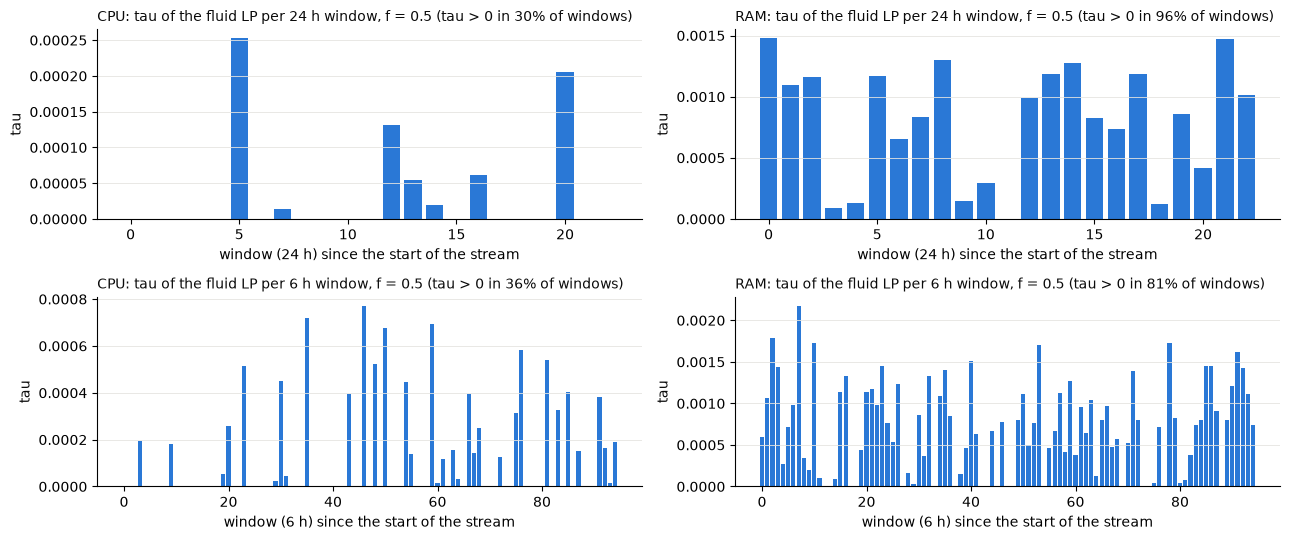

In [17]:
display(dg.benchmark_table(R0))
w24, w6 = R0["windows"][24], R0["windows"][6]
display(pd.DataFrame({"windows": [len(w24), len(w6)], "tau CPU > 0 %": [100 * (w24[:, 0] > 0).mean(), 100 * (w6[:, 0] > 0).mean()],
                      "tau RAM > 0 %": [100 * (w24[:, 1] > 0).mean(), 100 * (w6[:, 1] > 0).mean()]}, index=["1 day", "6 h"]))
fig, axs = plt.subplots(2, 2, figsize=(13, 5.5))
te.fig_tau_windows(R0, axs[0], hours=24)
te.fig_tau_windows(R0, axs[1], hours=6)
plt.tight_layout(); plt.show()

In [18]:
HS = te.h_vs_stream(B, ST, CFG)
display(pd.Series({"Phase 0 LP, expected $": HS["phase0_expected"],
                   "LP on the stream's statistics (Phase 0 grid) $": HS["stream_stats_phase0_grid_opt"],
                   "Phase 0's x on the stream's statistics $": HS["phase0_x_on_stream_stats"],
                   "fluid OPT $": HS["fluid_opt"], "arrival rate, stream / H (weighted)": HS["lambda_ratio"],
                   "mean r x d, stream / H (weighted)": HS["rd_ratio"]}, name="value").to_frame())

,value
"Phase 0 LP, expected $","2,915.23"
LP on the stream's statistics (Phase 0 grid) $,"2,832.99"
Phase 0's x on the stream's statistics $,"1,166.26"
fluid OPT $,"2,843.68"
"arrival rate, stream / H (weighted)",1.53181
"mean r x d, stream / H (weighted)",1.0432


**The one-week bucketed MILP** (the first 7 days of the stream; reference buckets, true durations; its own HiGHS
instance with a 3,600 s limit). The fluid LP on a window counts only the volume inside the window (D6).

In [19]:
WEEK = cached("week_milp.pkl", "week")
show(dg.checks_week(WEEK))
best, bound = WEEK["bucketed_believed"], min(WEEK["bucketed_dual_bound"], WEEK["bucketed_lp_believed"])
display(pd.Series({"jobs": WEEK["n_jobs"], "MILP candidates": WEEK["n_candidates"], "nonzeros": WEEK["nonzeros"],
                   "fluid OPT, volume inside the window $": WEEK["fluid"],
                   "fluid on feasible types, inside the window $": WEEK["fluid_feasible"],
                   "fluid OPT, whole volume $": WEEK["fluid_whole_volume"], "MILP best $": best, "MILP bound $": bound,
                   "MILP gap %": 100 * WEEK["gap"], "MILP runtime s": WEEK["milp_runtime_s"],
                   "discretization cost $ (best .. bound)": f"{WEEK['fluid_feasible'] - best:,.2f} .. {WEEK['fluid_feasible'] - bound:,.2f}",
                   "discretization cost %": f"{100 * (WEEK['fluid_feasible'] - best) / WEEK['fluid_feasible']:.2f} .. "
                                            f"{100 * (WEEK['fluid_feasible'] - bound) / WEEK['fluid_feasible']:.2f}",
                   "MILP realised (job rewards) $": WEEK["bucketed_realised"]}, name="value").to_frame())

,check,result,detail
0,fluid (inside the window) >= fluid on feasible...,PASS,912.19 >= 912.19
1,fluid on feasible types (inside the window) >=...,PASS,912.19 >= 867.81
2,MILP bound >= MILP best,PASS,867.81 >= 862.59
3,the MILP's chosen set is feasible on the true ...,PASS,
4,"the MILP used its own 3,600 s budget",PASS,"3601 s, gap 0.61%"


,value
jobs,58201
MILP candidates,46724
nonzeros,6844148
"fluid OPT, volume inside the window $",912.187
"fluid on feasible types, inside the window $",912.187
"fluid OPT, whole volume $",904.905
MILP best $,862.589
MILP bound $,867.814
MILP gap %,0.605743
MILP runtime s,"3,600.89"


## 10. One theoretical DLENT-RT run

The theoretical model with the default config (seed 42): frozen oracle, thinning after the LP decision, physical
gate, Tests 1–3, ReInit, threshold payments. The run is cached. The tables below check each decision on the logs.

In [20]:
show(dg.checks_run(RUN, CFG),
     {("D5", "frozen oracle; live switch"): ["frozen oracle: every score uses the phase's r~ (no live price)",
                                            "frozen oracle: k_hat = 1[r~ - tau v > 0]"],
      ("D5", "thinning after the LP decision"): ["admit = k_hat and U and fits (thinning after the LP decision, then the gate)",
                                                 "thinned count = k_hat and not U"],
      ("D5", "ReInit: all arrivals vs admitted"): ["ReInit statistics: rates, bids, sigma, requests from ALL arrivals of the phase",
                                                   "ReInit statistics: duration, energy, costs from ADMITTED jobs only"],
      ("D4", "grid rebuilt at every ReInit"): ["grid rebuilt at every ReInit with >= n_min arrivals"],
      ("D6", "threshold payment = lowest admitted bin's lower edge"): ["payment = lower edge of the lowest admitted bin of (q, hw) at the phase's tau"],
      ("D6", "surplus, realised profit, IR"): ["IR: payment <= bid for every admitted job"],
      ("D5", "timeout at 2 x the previous phase length"): ["tests start d_max after the phase start; timeout at 2 x the previous phase length"]})
display(dg.phase_table(RUN["phases"], CFG.time.tick_seconds))

,check,result,detail
0,frozen oracle: every score uses the phase's r~...,PASS,
1,frozen oracle: k_hat = 1[r~ - tau v > 0],PASS,
2,admit = k_hat and U and fits (thinning after t...,PASS,"101,449 admitted"
3,thinning does not depend on the decision (U ra...,PASS,0.653 vs 0.651
4,thinned count = k_hat and not U,PASS,"55,631"
5,"ReInit statistics: rates, bids, sigma, request...",PASS,
6,"ReInit statistics: duration, energy, costs fro...",PASS,
7,grid rebuilt at every ReInit with >= n_min arr...,PASS,
8,payment = lower edge of the lowest admitted bi...,PASS,
9,IR: payment <= bid for every admitted job,PASS,"0 of 101,449 violate"


,phase,start (h),end (h),length (h),reason,arrivals,admitted,tau CPU,tau RAM,rho,sigma,reward $,payments $,IR violations,next grid rebuilt,next rho,next sigma,"ReInit: arrivals used (p, v, sigma, A)","ReInit: admitted used (d, energy, costs)"
0,1,0,48,48,timeout,15804,6797,0,0.000734889,1.08831,0.300994,76.0718,7.40854,0,True,1.08711,0.301411,"15,804","6,797"
1,2,48,72.0731,24.0731,test2,7950,3742,0,0.000261032,1.08711,0.301411,54.658,4.07145,0,True,1.08631,0.301,"7,950","3,742"
2,3,72.0731,111.073,39,test2,14297,6937,0,0.000222183,1.08631,0.301,10.4791,7.25599,0,True,1.07836,0.296098,"14,297","6,937"
3,4,111.073,136.028,24.9553,test2,9025,4441,0,0,1.07836,0.296098,-9.64528,4.38262,0,True,1.07994,0.300878,"9,025","4,441"
4,5,136.028,185.939,49.9106,timeout,16433,7303,0,0.00095278,1.07994,0.300878,54.2487,7.31866,0,True,1.08442,0.298212,"16,433","7,303"
5,6,185.939,237.063,51.1244,test1,11854,5765,0,0,1.08442,0.298212,85.0903,6.67639,0,True,1.08047,0.296521,"11,854","5,765"
6,7,237.063,261.182,24.1186,test2,5585,2604,0,0.000126034,1.08047,0.296521,30.4335,2.5635,0,True,1.08185,0.300908,"5,585","2,604"
7,8,261.182,306.084,44.9019,test1,11047,5162,0,0,1.08185,0.300908,69.5675,5.28693,0,True,1.08957,0.298877,"11,047","5,162"
8,9,306.084,330.175,24.0914,test2,11870,5913,0,0,1.08957,0.298877,45.8507,6.02228,0,True,1.07833,0.299432,"11,870","5,913"
9,10,330.175,375.857,45.6814,test1,26937,10842,0,0.000962675,1.07833,0.299432,90.4999,12.8515,0,True,1.08252,0.299276,"26,937","10,842"


In [21]:
A = RUN["arrivals"]
adm = A[A.admit]
sm = RUN["summary"]
static, nl = R0["static"]["split"], R0["no_learning"]["split"]
tot = pd.DataFrame({
    "DLENT-RT (theoretical)": [sm["R_total"], adm.R.sum(), sm["SW_total"], sm["n_admitted"]],
    "static Phase 0 policy": [static["reward"], static["reward"], static["social welfare"], R0["static"]["n_admitted"]],
    "no-learning model": [nl["reward"], nl["reward"], nl["social welfare"], R0["no_learning"]["n_admitted"]],
    "fluid OPT": [R0["fluid"]["split"]["reward"], np.nan, np.nan, np.nan]},
    index=["reward $", "reward $ (sum of admitted R)", "social welfare $", "jobs admitted"])
display(tot)
split = pd.DataFrame({"customer value $": [float(TERMS.cv[adm.i].sum())],
                      "profit $ (phi - C_elec)": [float(TERMS.profit[adm.i].sum())],
                      "carbon $": [-float(TERMS.carbon_usd[adm.i].sum())],
                      "payments $": [sm["payments_total"]], "customer surplus v - p $": [sm["surplus_total"]],
                      "realised profit p - C_elec $": [sm["profit_realised_total"]],
                      "IR violations": [sm["n_ir_violations"]], "phases": [sm["n_phases"]],
                      "end reasons": [str(sm["phase_end_reasons"])], "Tests 2-3 reward unit r_max $": [RUN["r_unit"]],
                      "runtime s": [RUN["runtime_s"]]}, index=["DLENT-RT"]).T
display(split)

,DLENT-RT (theoretical),static Phase 0 policy,no-learning model,fluid OPT
reward $,720.546,"1,316.92",901.942,"2,843.68"
reward $ (sum of admitted R),720.546,"1,316.92",901.942,NaN
social welfare $,286.461,474.536,275.324,NaN
jobs admitted,"101,449","129,626","96,374",NaN


,DLENT-RT
customer value $,"1,603.96"
profit $ (phi - C_elec),428.199
carbon $,"-1,311.61"
payments $,119.948
customer surplus v - p $,"1,484.01"
realised profit p - C_elec $,114.062
IR violations,0
phases,16
end reasons,"{'test1': 6, 'test2': 7, 'test3': 0, 'timeout'..."
Tests 2-3 reward unit r_max $,0.00552106


In [22]:
viol = adm[~adm.ir]
display(Markdown(f"**IR violations: {len(viol):,} of {len(adm):,} admitted jobs.**"))
if len(viol):
    display(viol[["i", "m", "k_bin", "q", "hw", "v", "payment", "threshold_k", "cost_base"]].head(10))
off = adm[adm.below_grid | adm.above_grid]
display(Markdown(f"Admitted bids outside the phase grid's [v_min, v_max]: {int(adm.below_grid.sum()):,} below, "
                 f"{int(adm.above_grid.sum()):,} above; the largest payment / bid among them is "
                 f"{(off.payment / off.v).max() if len(off) else float('nan'):.3f}."))

**IR violations: 0 of 101,449 admitted jobs.**

Admitted bids outside the phase grid's [v_min, v_max]: 0 below, 9 above; the largest payment / bid among them is 0.001.

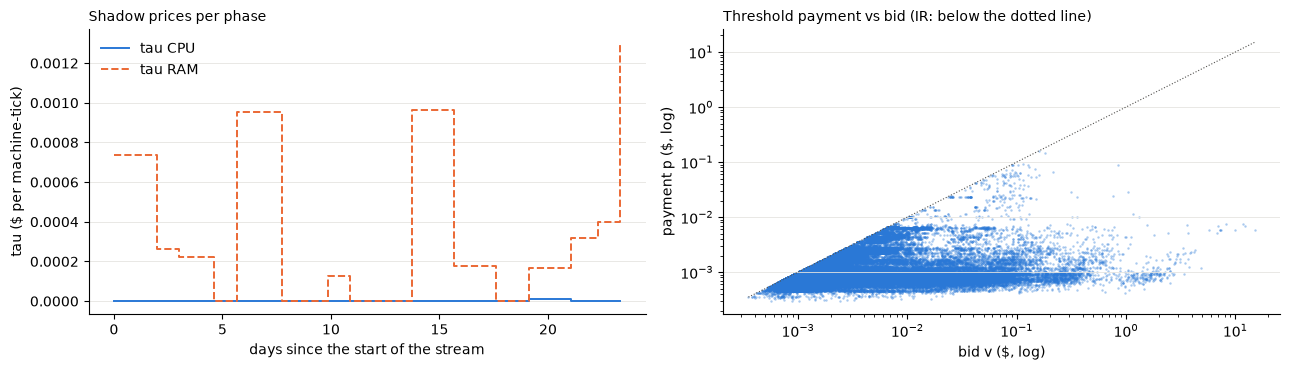

In [23]:
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
ph = RUN["phases"]
h = CFG.time.tick_seconds / 3600
axs[0].step(ph.tau_start * h / 24, ph.tau_cpu, where="post", color=BLUE, lw=1.4, label="tau CPU")
axs[0].step(ph.tau_start * h / 24, ph.tau_ram, where="post", color=ORANGE, lw=1.4, ls="--", label="tau RAM")
style(axs[0], "days since the start of the stream", "tau ($ per machine-tick)")
axs[0].set_title("Shadow prices per phase", loc="left", fontsize=10)
axs[0].legend(frameon=False)
axs[1].scatter(adm.v, adm.payment, s=3, color=BLUE, alpha=0.4, lw=0)
lim = [adm.v.min(), adm.v.max()]
axs[1].plot(lim, lim, color=INK2, lw=0.8, ls=":")
axs[1].set_xscale("log"); axs[1].set_yscale("log")
style(axs[1], "bid v ($, log)", "payment p ($, log)")
axs[1].set_title("Threshold payment vs bid (IR: below the dotted line)", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

## 11. D1–D6 checklist

Each row names the code (file and line, found by searching the source) and the result of the notebook's checks.
An empty result means the item is checked by reading the code (and by the tests), not by a number here.

In [24]:
display(dg.checklist(RESULTS))

,decision,what,where,notebook
0,D1,V = v (no q factor); Pi = phi - C_elec; carbon...,dlent_rt/reward.py:62,PASS
1,D1,"R = l1 V + l2 Pi - l3 s_C K, linear, all lambd...",dlent_rt/reward.py:138,PASS
2,D1,"s_C = D_q / K_q over H's types, once in Phase 0",dlent_rt/reward.py:112,PASS
3,D1,SW metric only,dlent_rt/reward.py:66,PASS
4,D1,Chebyshev only in the offline Pareto code,dlent_rt/pareto.py:15,
5,D2,cost_base = (U0 (1 + ln q) + g1 cores + g2 GB) d,dlent_rt/bid.py:97,PASS
6,D2,U0 = rate of the median H job,dlent_rt/bid.py:84,PASS
7,D2,phi = cost_base phi_m(v / cost_base),dlent_rt/bid.py:37,PASS
8,D2,sigma refit in Phase 0,dlent_rt/phase0.py:261,PASS
9,D2,sigma refit at ReInit,dlent_rt/models/core/reinit.py:71,PASS
